Upload prepared_hourly_data.csv


Saving prepared_hourly_data.csv to prepared_hourly_data (1).csv

Dataset loaded successfully!
Original dataset shape: (34159, 11)
Clean dataset shape: (34159, 10)
Input features: 9

DATA SPLIT
Training records: 27327
Testing records: 6832

Training ANN on the complete training set...
Iteration 1, loss = 0.28602115
Iteration 2, loss = 0.19279434
Iteration 3, loss = 0.18100576
Iteration 4, loss = 0.17491865
Iteration 5, loss = 0.17066842
Iteration 6, loss = 0.16725841
Iteration 7, loss = 0.16414889
Iteration 8, loss = 0.16240276
Iteration 9, loss = 0.16066901
Iteration 10, loss = 0.15867574
Iteration 11, loss = 0.15755837
Iteration 12, loss = 0.15642711
Iteration 13, loss = 0.15474846
Iteration 14, loss = 0.15389051
Iteration 15, loss = 0.15299989
Iteration 16, loss = 0.15273793
Iteration 17, loss = 0.15194237
Iteration 18, loss = 0.15033966
Iteration 19, loss = 0.15015035
Iteration 20, loss = 0.14919165
Iteration 21, loss = 0.14895106
Iteration 22, loss = 0.14905642
Iteration 23, loss =

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


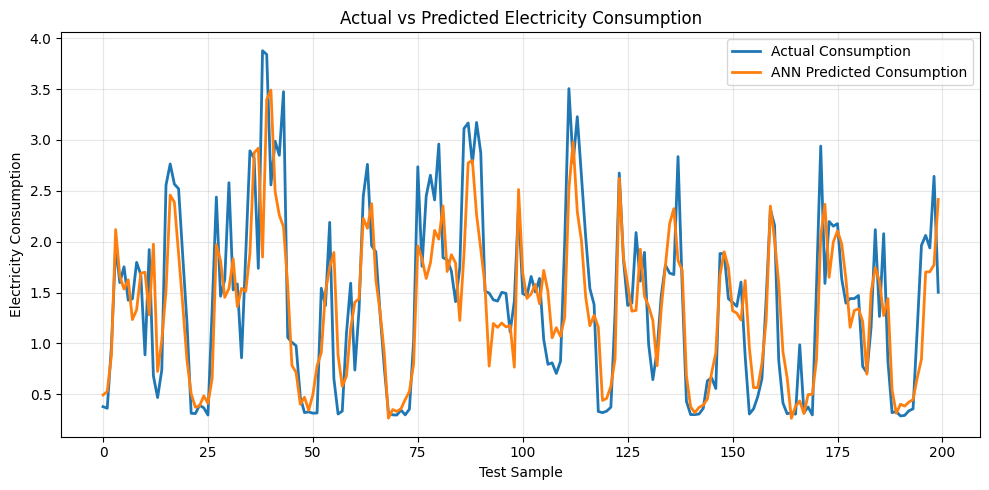


========== FIRST 10 PREDICTIONS ==========
 Actual_Consumption  ANN_Prediction  Baseline_Prediction
             0.3780          0.4930               0.4042
             0.3624          0.5271               0.3780
             0.9718          0.8839               0.3624
             1.9550          2.1190               0.9718
             1.5980          1.6616               1.9550
             1.7534          1.5343               1.5980
             1.4250          1.6256               1.7534
             1.4377          1.2345               1.4250
             1.7966          1.3298               1.4377
             1.6752          1.6902               1.7966

All results generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# SMART ELECTRICITY CONSUMPTION ADVISOR
# MEMBER 2: ANN MODEL AND CONSUMPTION PREDICTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# STEP 1: UPLOAD THE PREPARED DATASET
print("Upload prepared_hourly_data.csv")
uploaded = files.upload()

# Automatically identify the prepared dataset
matches = [
    name for name in uploaded.keys()
    if "prepared_hourly_data" in name.lower()
    and name.lower().endswith(".csv")
]

if not matches:
    raise ValueError(
        "Please upload prepared_hourly_data.csv "
        "and run this cell again."
    )

filename = matches[0]
data = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("Original dataset shape:", data.shape)

# STEP 2: SELECT FEATURES AND TARGET
target = "target_next_hour"

features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
    "hour",
    "day_of_week"
]

if target not in data.columns:
    raise ValueError(
        f"Target '{target}' not found. "
        f"Available columns: {data.columns.tolist()}"
    )

missing = [col for col in features if col not in data.columns]

if missing:
    raise ValueError(
        f"Missing feature columns: {missing}. "
        "Check the actual column names in your CSV."
    )

data = data[features + [target]].copy()

# Convert columns to numeric and remove invalid rows
for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna().reset_index(drop=True)

print("Clean dataset shape:", data.shape)
print("Input features:", len(features))

# STEP 3: CREATE CHRONOLOGICAL TRAIN/TEST SPLIT
# First 80% = training, last 20% = testing
split_index = int(len(data) * 0.80)

train_data = data.iloc[:split_index]
test_data = data.iloc[split_index:]

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("\nDATA SPLIT")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# STEP 4: SCALE INPUT FEATURES
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# STEP 5: BUILD THE ANN MODEL
# Two hidden layers: 64 and 32 neurons
ann = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=50,
    early_stopping=False,
    random_state=42,
    verbose=True
)

# STEP 6: TRAIN ON ALL TRAINING RECORDS
print("\nTraining ANN on the complete training set...")

ann.fit(X_train_scaled, y_train)

print("\nANN training completed!")

# STEP 7: PREDICT TEST CONSUMPTION
y_pred = ann.predict(X_test_scaled)

# STEP 8: CALCULATE ANN METRICS
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== ANN RESULTS ==========")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# STEP 9: BASELINE COMPARISON
# Predict next-hour consumption using current-hour power
baseline = X_test["Global_active_power"].to_numpy()

base_mae = mean_absolute_error(y_test, baseline)
base_rmse = np.sqrt(mean_squared_error(y_test, baseline))
base_r2 = r2_score(y_test, baseline)

print("\n========== BASELINE RESULTS ==========")
print(f"MAE  : {base_mae:.4f}")
print(f"RMSE : {base_rmse:.4f}")
print(f"R2   : {base_r2:.4f}")

# STEP 10: COMPARE ANN AND BASELINE
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "ANN": [mae, rmse, r2],
    "Baseline": [base_mae, base_rmse, base_r2]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.to_string(index=False))

# STEP 11: ACTUAL VS PREDICTED GRAPH
n = min(200, len(y_test))

plt.figure(figsize=(10, 5))

plt.plot(
    np.asarray(y_test)[:n],
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    y_pred[:n],
    label="ANN Predicted Consumption",
    linewidth=2
)

plt.xlabel("Test Sample")
plt.ylabel("Electricity Consumption")
plt.title("Actual vs Predicted Electricity Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

# STEP 12: SAVE PREDICTIONS
results = pd.DataFrame({
    "Actual_Consumption": np.asarray(y_test),
    "ANN_Prediction": y_pred,
    "Baseline_Prediction": baseline
})

results.to_csv("ann_prediction_results.csv", index=False)
comparison.to_csv("ann_model_comparison.csv", index=False)

# STEP 13: DISPLAY SAMPLE PREDICTIONS
print("\n========== FIRST 10 PREDICTIONS ==========")

print(
    results.head(10).round(4).to_string(index=False)
)

print("\nAll results generated successfully!")

# STEP 14: DOWNLOAD OUTPUT FILES
files.download("actual_vs_predicted.png")
files.download("ann_prediction_results.csv")
files.download("ann_model_comparison.csv")
